# CSET485 – AI and Society | Assignment #1
**Roll Number:** `S24BCAU0139`  
**Assigned Dataset:** UCI Adult Census Income (`adult.data`)  
**Random Seed (`random_state`):** `139` (Stratified 70% Train / 30% Test Split)

This notebook reproduces every statistic, regression coefficient, confidence interval, p-value, adversarial subset diagnostic, fairness metric sweep, and chart reported in `S24BCAU0139_CSET485_Assignment1_Report.pdf` from start to finish.


## Section 1: Data Loading & Preprocessing
We load the official UCI Adult Census Income dataset (`32,561` rows, `15` attributes), audit missing `?` values, drop `fnlwgt` (census sampling weight) and `education` (redundant with `education-num`), apply `np.log1p` to right-skewed `capital-gain` and `capital-loss` (mitigating the `99,999` top-code outlier), encode binary/categorical features (`drop_first=True`), perform a stratified 70/30 split with `random_state=139`, and fit `StandardScaler` strictly on the training split.


In [1]:
%matplotlib inline
import json
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({
    'figure.dpi': 140,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'axes.labelsize': 9.5,
})

RANDOM_STATE = 139
DATA_URL = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data'
DATA_PATH = Path('data/adult.data')
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists() or DATA_PATH.stat().st_size == 0:
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

COLUMNS = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'sex',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]
NUMERIC_COLS = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
CAT_COLS = ['workclass', 'marital-status', 'occupation', 'relationship', 'race']

raw_df = pd.read_csv(DATA_PATH, names=COLUMNS, skipinitialspace=True, na_values='?')
print(f'Raw shape: {raw_df.shape}')
print('Missing values per column:')
print(raw_df.isna().sum()[raw_df.isna().sum() > 0])
incomplete = raw_df.isna().any(axis=1).sum()
print(f'Incomplete rows: {incomplete} ({incomplete / len(raw_df) * 100:.2f}%)')

clean_df = raw_df.dropna().copy().reset_index(drop=True)
clean_df['y'] = (clean_df['income'] == '>50K').astype(int)
print(f'Clean complete-case shape: {clean_df.shape} | Positive (>50K) rate: {clean_df["y"].mean()*100:.2f}%')
print(f'capital-gain == 99999 count: {(clean_df["capital-gain"] == 99999).sum()}')

def build_feature_matrix(df, drop_cols=None):
    drop_set = set(drop_cols or [])
    d = df.copy()
    d['sex_male'] = (d['sex'] == 'Male').astype(float)
    d['is_us'] = (d['native-country'] == 'United-States').astype(float)
    d['capital-gain'] = np.log1p(d['capital-gain'])
    d['capital-loss'] = np.log1p(d['capital-loss'])
    num_cols = [c for c in NUMERIC_COLS if c not in drop_set]
    cat_cols = [c for c in CAT_COLS if c not in drop_set]
    parts = [d[num_cols]]
    if 'sex' not in drop_set:
        parts.append(d[['sex_male']])
    if 'native-country' not in drop_set:
        parts.append(d[['is_us']])
    if cat_cols:
        parts.append(pd.get_dummies(d[cat_cols], drop_first=True, dtype=float))
    return pd.concat(parts, axis=1), num_cols

X_all, num_cols = build_feature_matrix(clean_df)
y_all = clean_df['y'].values
idx = np.arange(len(clean_df))
tr_idx, te_idx = train_test_split(idx, test_size=0.30, random_state=RANDOM_STATE, stratify=y_all)

scaler = StandardScaler()
X_tr = X_all.iloc[tr_idx].copy()
X_te = X_all.iloc[te_idx].copy()
X_tr[num_cols] = scaler.fit_transform(X_tr[num_cols])
X_te[num_cols] = scaler.transform(X_te[num_cols])
y_tr, y_te = y_all[tr_idx], y_all[te_idx]
print(f'Train rows: {len(X_tr):,} | Test rows: {len(X_te):,} | Feature count: {X_tr.shape[1]}')


Raw shape: (32561, 15)
Missing values per column:
workclass         1836
occupation        1843
native-country     583
dtype: int64
Incomplete rows: 2399 (7.37%)
Clean complete-case shape: (30162, 16) | Positive (>50K) rate: 24.89%
capital-gain == 99999 count: 148
Train rows: 21,113 | Test rows: 9,049 | Feature count: 41


## Section 2: Part 1 — Build & Compare Models
We fit **Model A (Linear Regression / OLS)** and **Model B (Logistic Regression)** on identical training data (`n = 21,113`), then evaluate both on the held-out test set (`n = 9,049`) using the median OLS threshold vs. the `0.50` probability threshold.


Model A OLS range: [-0.3424, 1.1949], median = 0.2315
Model A out-of-bounds (<0 or >1): 1884 (20.82%)
Model A (median) accuracy vs y: 71.92% | High-risk flagged: 4,525 (50.01%)
Model B (0.50)   accuracy vs y: 84.78% | AUC: 0.9013 | High-risk flagged: 1,841 (20.34%)
Agreement Confusion Matrix (rows=Model A, cols=Model B):
                 B: Low (<0.5)  B: High (>=0.5)
A: Low (<med)             4524                0
A: High (>=med)           2684             1841
Mismatched individuals: 2,684 / 9,049 (29.66%)


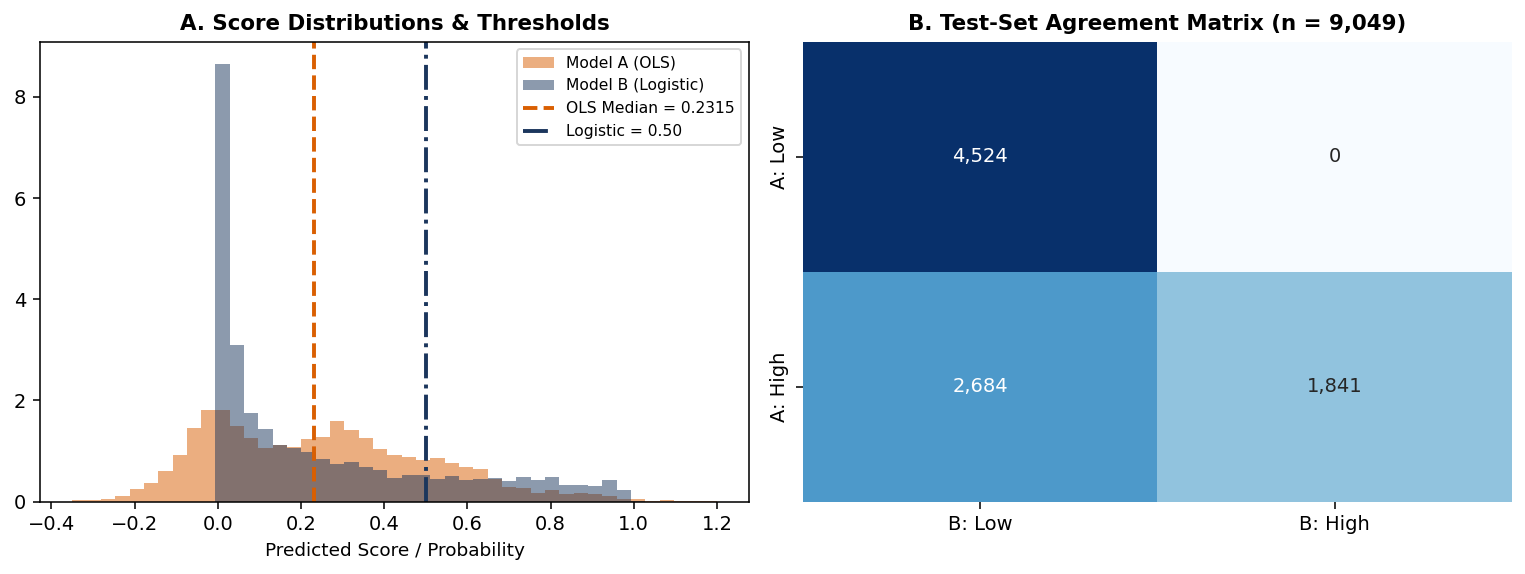

In [2]:
def fit_logit_with_wald(X_df, y_vec):
    model = LogisticRegression(max_iter=3000, C=1e6, solver='lbfgs', random_state=RANDOM_STATE)
    model.fit(X_df, y_vec)
    p = model.predict_proba(X_df)[:, 1]
    w = p * (1.0 - p)
    Xd = np.column_stack([np.ones(len(X_df)), X_df.values])
    cov = np.linalg.pinv((Xd.T * w) @ Xd)
    se = np.sqrt(np.maximum(np.diag(cov)[1:], 1e-12))
    coef = model.coef_[0]
    z = coef / se
    pval = 2.0 * (1.0 - stats.norm.cdf(np.abs(z)))
    return model, pd.DataFrame({
        'coef': coef, 'se': se, 'z': z, 'p_value': pval,
        'ci_lo': coef - 1.96 * se, 'ci_hi': coef + 1.96 * se
    }, index=X_df.columns)

ols = LinearRegression().fit(X_tr, y_tr)
pred_ols = ols.predict(X_te)
med_ols = float(np.median(pred_ols))
flag_a = (pred_ols >= med_ols).astype(int)

lr_full, wald_full = fit_logit_with_wald(X_tr, y_tr)
prob_b = lr_full.predict_proba(X_te)[:, 1]
flag_b = (prob_b >= 0.50).astype(int)

cm_ab = confusion_matrix(flag_a, flag_b)
mismatch = int((flag_a != flag_b).sum())
oob = ((pred_ols < 0) | (pred_ols > 1)).sum()

print(f'Model A OLS range: [{pred_ols.min():.4f}, {pred_ols.max():.4f}], median = {med_ols:.4f}')
print(f'Model A out-of-bounds (<0 or >1): {oob} ({oob/len(pred_ols)*100:.2f}%)')
print(f'Model A (median) accuracy vs y: {accuracy_score(y_te, flag_a)*100:.2f}% | High-risk flagged: {flag_a.sum():,} ({flag_a.mean()*100:.2f}%)')
print(f'Model B (0.50)   accuracy vs y: {accuracy_score(y_te, flag_b)*100:.2f}% | AUC: {roc_auc_score(y_te, prob_b):.4f} | High-risk flagged: {flag_b.sum():,} ({flag_b.mean()*100:.2f}%)')
print('Agreement Confusion Matrix (rows=Model A, cols=Model B):')
print(pd.DataFrame(cm_ab, index=['A: Low (<med)', 'A: High (>=med)'], columns=['B: Low (<0.5)', 'B: High (>=0.5)']))
print(f'Mismatched individuals: {mismatch:,} / {len(y_te):,} ({mismatch/len(y_te)*100:.2f}%)')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bins = np.linspace(-0.35, 1.20, 46)
axes[0].hist(pred_ols, bins=bins, density=True, alpha=0.5, color='#D95F02', label='Model A (OLS)')
axes[0].hist(prob_b, bins=bins, density=True, alpha=0.5, color='#1B365D', label='Model B (Logistic)')
axes[0].axvline(med_ols, color='#D95F02', ls='--', lw=2, label=f'OLS Median = {med_ols:.4f}')
axes[0].axvline(0.50, color='#1B365D', ls='-.', lw=2, label='Logistic = 0.50')
axes[0].set_title('A. Score Distributions & Thresholds')
axes[0].set_xlabel('Predicted Score / Probability')
axes[0].legend(fontsize=8)
sns.heatmap(cm_ab, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['B: Low', 'B: High'], yticklabels=['A: Low', 'A: High'], ax=axes[1])
axes[1].set_title('B. Test-Set Agreement Matrix (n = 9,049)')
plt.tight_layout()
plt.show()


## Section 3: Part 2.1 — Simpson's Paradox Hunt
We split the training data by age (`Subgroup A: Age < 45` vs. `Subgroup B: Age ≥ 45`) and fit identical logistic regressions on the full set and both subgroups to test whether the `age` trend reverses sign.


     Predictor        Model    Coef  95% CI Low  95% CI High  p-value
           age Full Dataset  0.3473      0.2968       0.3979 0.00e+00
           age     Age < 45  1.0783      0.9480       1.2087 0.00e+00
           age    Age >= 45 -0.4141     -0.5365      -0.2917 3.34e-11
 education-num Full Dataset  0.7129      0.6570       0.7688 0.00e+00
 education-num     Age < 45  0.7257      0.6451       0.8063 0.00e+00
 education-num    Age >= 45  0.6312      0.5516       0.7107 0.00e+00
hours-per-week Full Dataset  0.3605      0.3138       0.4073 0.00e+00
hours-per-week     Age < 45  0.3278      0.2628       0.3928 0.00e+00
hours-per-week    Age >= 45  0.2851      0.2139       0.3564 4.22e-15
      sex_male Full Dataset  0.7890      0.6110       0.9669 0.00e+00
      sex_male     Age < 45  0.6230      0.3920       0.8540 1.25e-07
      sex_male    Age >= 45  1.1027      0.8151       1.3902 5.64e-14
  capital-gain Full Dataset  0.4894      0.4509       0.5278 0.00e+00
  capital-gain     A

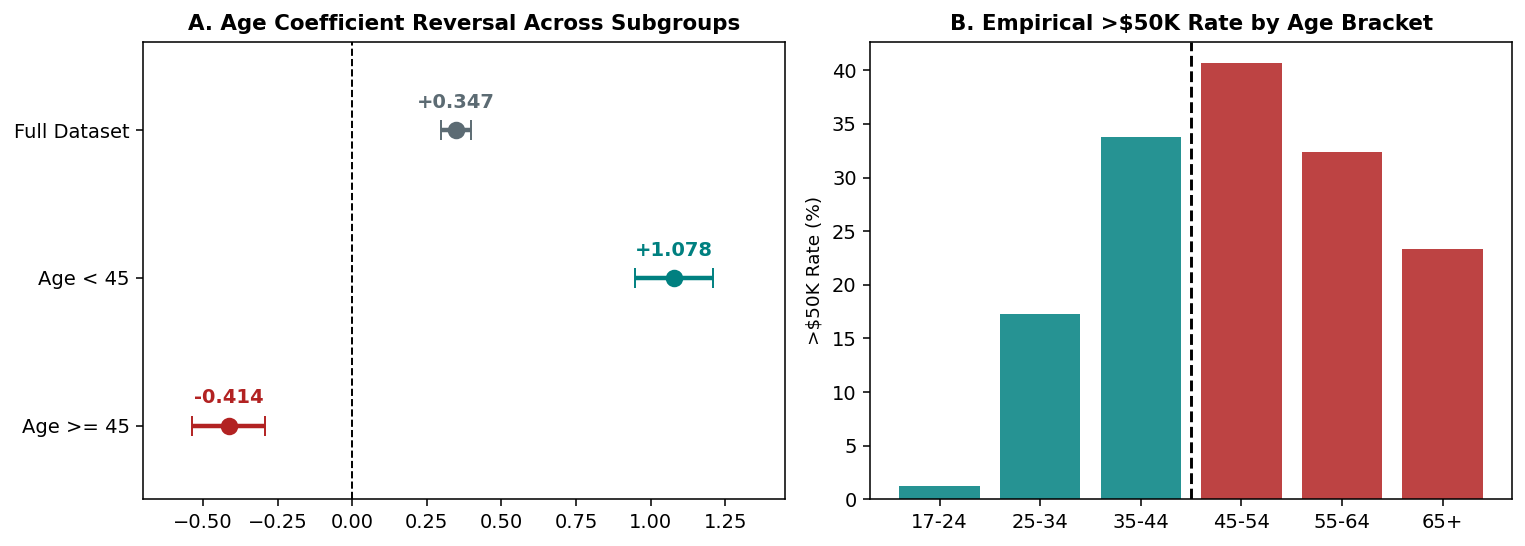

In [3]:
df_tr_raw = clean_df.iloc[tr_idx].copy().reset_index(drop=True)
mask_young = (df_tr_raw['age'] < 45).values
mask_older = ~mask_young
XA, XB = X_tr[mask_young], X_tr[mask_older]
valid_cols = [c for c in X_tr.columns if XA[c].std() > 1e-6 and XB[c].std() > 1e-6]

_, wald_young = fit_logit_with_wald(XA[valid_cols], y_tr[mask_young])
_, wald_older = fit_logit_with_wald(XB[valid_cols], y_tr[mask_older])

rows_s = []
for pred in ['age', 'education-num', 'hours-per-week', 'sex_male', 'capital-gain']:
    for label, tbl in [('Full Dataset', wald_full), ('Age < 45', wald_young), ('Age >= 45', wald_older)]:
        r = tbl.loc[pred]
        rows_s.append({
            'Predictor': pred, 'Model': label,
            'Coef': round(r['coef'], 4), '95% CI Low': round(r['ci_lo'], 4),
            '95% CI High': round(r['ci_hi'], 4), 'p-value': f"{r['p_value']:.2e}"
        })
simpson_df = pd.DataFrame(rows_s)
print(simpson_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
age_sub = simpson_df[simpson_df['Predictor'] == 'age']
yp = np.arange(3)[::-1]
cols_p = ['#5C6B73', '#008080', '#B22222']
for pos, (_, row), c in zip(yp, age_sub.iterrows(), cols_p):
    axes[0].errorbar(row['Coef'], pos, xerr=[[row['Coef']-row['95% CI Low']], [row['95% CI High']-row['Coef']]],
                     fmt='o', color=c, lw=2.3, capsize=5, ms=8)
    axes[0].text(row['Coef'], pos+0.15, f"{row['Coef']:+.3f}", ha='center', fontweight='bold', color=c)
axes[0].axvline(0, color='black', ls='--', lw=1)
axes[0].set_yticks(yp); axes[0].set_yticklabels(age_sub['Model'])
axes[0].set_ylim(-0.5, 2.6); axes[0].set_xlim(-0.7, 1.45)
axes[0].set_title('A. Age Coefficient Reversal Across Subgroups')

bins_age = [('17-24',17,24), ('25-34',25,34), ('35-44',35,44), ('45-54',45,54), ('55-64',55,64), ('65+',65,100)]
rates = [df_tr_raw[(df_tr_raw['age']>=lo)&(df_tr_raw['age']<=hi)]['y'].mean()*100 for _,lo,hi in bins_age]
axes[1].bar([b[0] for b in bins_age], rates, color=['#008080']*3 + ['#B22222']*3, alpha=0.85)
axes[1].axvline(2.5, color='black', ls='--')
axes[1].set_title('B. Empirical >$50K Rate by Age Bracket')
axes[1].set_ylabel('>$50K Rate (%)')
plt.tight_layout()
plt.show()


## Section 4: Part 2.2 — Omitted-Variable Bias
We deliberately drop `education-num` from the logistic regression model and quantify the resulting percentage bias across 6 key predictors.


Full Model Test Acc: 84.78% | AUC: 0.9013
Reduced Model Test Acc: 83.21% | AUC: 0.8881
                 Predictor  Full Coef  Reduced Coef  Abs Diff  Pct Shift (%)
 occupation_Prof-specialty     0.5324        1.2105    0.6781         127.37
occupation_Exec-managerial     0.7976        1.0486    0.2509          31.46
                       age     0.3473        0.3002   -0.0472         -13.58
            hours-per-week     0.3605        0.3923    0.0318           8.82
                  sex_male     0.7890        0.8277    0.0387           4.91
              capital-gain     0.4894        0.4981    0.0087           1.79


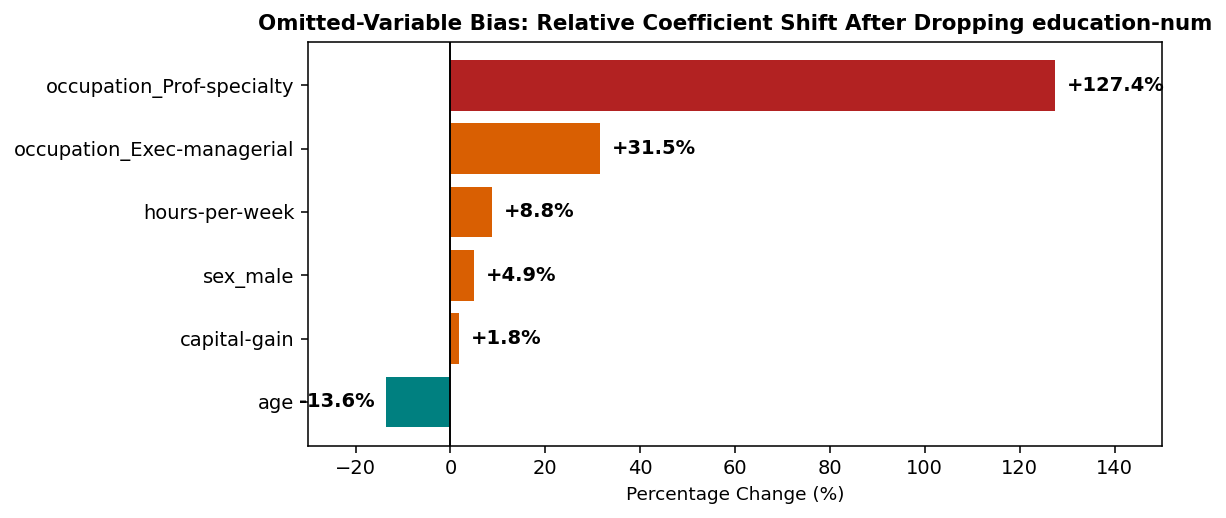

In [4]:
X_red_all, red_num = build_feature_matrix(clean_df, drop_cols=['education-num'])
sc_red = StandardScaler()
X_red_tr = X_red_all.iloc[tr_idx].copy()
X_red_te = X_red_all.iloc[te_idx].copy()
X_red_tr[red_num] = sc_red.fit_transform(X_red_tr[red_num])
X_red_te[red_num] = sc_red.transform(X_red_te[red_num])

lr_red, wald_red = fit_logit_with_wald(X_red_tr, y_tr)
prob_red = lr_red.predict_proba(X_red_te)[:, 1]
print(f'Full Model Test Acc: {accuracy_score(y_te, flag_b)*100:.2f}% | AUC: {roc_auc_score(y_te, prob_b):.4f}')
print(f'Reduced Model Test Acc: {accuracy_score(y_te, (prob_red>=0.5).astype(int))*100:.2f}% | AUC: {roc_auc_score(y_te, prob_red):.4f}')

ovb_feats = ['occupation_Prof-specialty', 'occupation_Exec-managerial', 'age', 'hours-per-week', 'sex_male', 'capital-gain']
ovb_rows = []
for f in ovb_feats:
    b0, b1 = wald_full.loc[f, 'coef'], wald_red.loc[f, 'coef']
    pct = (b1 - b0) / abs(b0) * 100
    ovb_rows.append({'Predictor': f, 'Full Coef': round(b0, 4), 'Reduced Coef': round(b1, 4), 'Abs Diff': round(b1-b0, 4), 'Pct Shift (%)': round(pct, 2)})
ovb_df = pd.DataFrame(ovb_rows)
print(ovb_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ord_df = ovb_df.sort_values('Pct Shift (%)')
cols_o = ['#B22222' if abs(v)>50 else ('#D95F02' if v>0 else '#008080') for v in ord_df['Pct Shift (%)']]
bars = ax.barh(ord_df['Predictor'], ord_df['Pct Shift (%)'], color=cols_o)
ax.axvline(0, color='black', lw=1)
for bar, v in zip(bars, ord_df['Pct Shift (%)']):
    ax.text(v + (2.5 if v>=0 else -2.5), bar.get_y()+bar.get_height()/2, f'{v:+.1f}%', va='center', ha=('left' if v>=0 else 'right'), fontweight='bold')
ax.set_xlim(-30, 150)
ax.set_title('Omitted-Variable Bias: Relative Coefficient Shift After Dropping education-num')
ax.set_xlabel('Percentage Change (%)')
plt.tight_layout()
plt.show()


## Section 5: Part 2.3 — Adversarial Subset Construction
We isolate all high-confidence wrong predictions on the test set (`P >= 0.75 & Y=0` or `P <= 0.25 & Y=1`), randomly sample 50 rows (`random_state=139`), and compare their shared traits against the full test set.


Total HC wrong predictions: 476 / 9049 (5.26%) [FP=111, FN=365]
Sampled 50 rows breakdown: FP=16, FN=34
             Trait  Adversarial (n=50) %  Full Test (n=9049) %
  Capital Loss = 0                  98.0                  95.3
         Age >= 30                  90.0                  71.0
             White                  88.0                  85.8
  Hours/Week >= 40                  86.0                  77.5
              Male                  80.0                  67.3
  Capital Gain = 0                  80.0                  91.4
Married-civ-spouse                  62.0                  46.6
FP sub-cluster (n=16): Married-civ=100.0%, Bachelors+=62.5%, CapGain>0=43.8%
FN sub-cluster (n=34): Zero CapGain&Loss=91.2%, No College Deg=79.4%, Not Married=55.9%


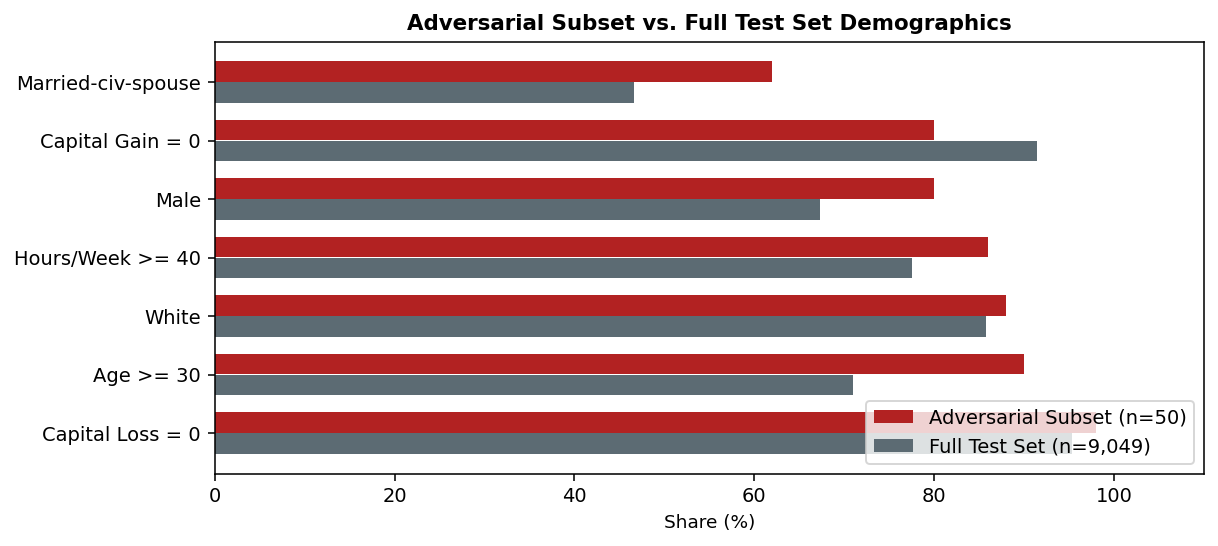

In [5]:
df_te_raw = clean_df.iloc[te_idx].copy().reset_index(drop=True)
df_te_raw['prob'] = prob_b
hc_fp = (df_te_raw['prob'] >= 0.75) & (df_te_raw['y'] == 0)
hc_fn = (df_te_raw['prob'] <= 0.25) & (df_te_raw['y'] == 1)
hc_err = hc_fp | hc_fn

adv = df_te_raw[hc_err].sample(n=min(50, hc_err.sum()), random_state=RANDOM_STATE)
print(f'Total HC wrong predictions: {hc_err.sum()} / {len(df_te_raw)} ({hc_err.mean()*100:.2f}%) [FP={hc_fp.sum()}, FN={hc_fn.sum()}]')
print(f'Sampled 50 rows breakdown: FP={(adv["y"]==0).sum()}, FN={(adv["y"]==1).sum()}')

traits = [
    ('Capital Loss = 0', lambda f: f['capital-loss'] == 0),
    ('Age >= 30', lambda f: f['age'] >= 30),
    ('White', lambda f: f['race'] == 'White'),
    ('Hours/Week >= 40', lambda f: f['hours-per-week'] >= 40),
    ('Male', lambda f: f['sex'] == 'Male'),
    ('Capital Gain = 0', lambda f: f['capital-gain'] == 0),
    ('Married-civ-spouse', lambda f: f['marital-status'] == 'Married-civ-spouse'),
]
comp_rows = [{'Trait': name, 'Adversarial (n=50) %': round(fn(adv).mean()*100, 1), 'Full Test (n=9049) %': round(fn(df_te_raw).mean()*100, 1)} for name, fn in traits]
comp_df = pd.DataFrame(comp_rows)
print(comp_df.to_string(index=False))

adv_fp, adv_fn = adv[adv['y']==0], adv[adv['y']==1]
print(f'FP sub-cluster (n={len(adv_fp)}): Married-civ={(adv_fp["marital-status"]=="Married-civ-spouse").mean()*100:.1f}%, Bachelors+={(adv_fp["education-num"]>=13).mean()*100:.1f}%, CapGain>0={(adv_fp["capital-gain"]>0).mean()*100:.1f}%')
print(f'FN sub-cluster (n={len(adv_fn)}): Zero CapGain&Loss={((adv_fn["capital-gain"]==0)&(adv_fn["capital-loss"]==0)).mean()*100:.1f}%, No College Deg={(adv_fn["education-num"]<=10).mean()*100:.1f}%, Not Married={(adv_fn["marital-status"]!="Married-civ-spouse").mean()*100:.1f}%')

fig, ax = plt.subplots(figsize=(8.8, 4.0))
y_pos = np.arange(len(comp_df))
ax.barh(y_pos + 0.18, comp_df['Adversarial (n=50) %'], height=0.35, color='#B22222', label='Adversarial Subset (n=50)')
ax.barh(y_pos - 0.18, comp_df['Full Test (n=9049) %'], height=0.35, color='#5C6B73', label='Full Test Set (n=9,049)')
ax.set_yticks(y_pos); ax.set_yticklabels(comp_df['Trait'])
ax.set_xlim(0, 110); ax.set_xlabel('Share (%)'); ax.set_title('Adversarial Subset vs. Full Test Set Demographics')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


## Section 6: Part 2.4 — Fairness Trade-Off Analysis
Using `sex` as the sensitive attribute (`Group A = Female`, `Group B = Male`), we sweep the decision threshold `t` from `0.05` to `0.95` in steps of `0.10`, compute Demographic Parity (DP), Equalized Odds (EO), Predictive Parity (PP), quantify the exact DP-vs-EO trade-off cost (`W/Z`), and inspect two real test-set case-study individuals.


   t    Acc    DP    EO    PP  TPR_F  TPR_M  FPR_F  FPR_M  PPV_F  PPV_M
0.05 0.6132 0.491 0.459 0.706  0.947  0.991  0.296  0.644  0.292  0.414
0.15 0.7488 0.337 0.279 0.929  0.817  0.947  0.120  0.430  0.467  0.502
0.25 0.8043 0.306 0.231 1.020  0.737  0.856  0.068  0.294  0.583  0.572
0.35 0.8341 0.303 0.248 0.967  0.618  0.767  0.048  0.192  0.626  0.647
0.45 0.8452 0.297 0.246 0.971  0.533  0.671  0.031  0.127  0.687  0.707
0.55 0.8444 0.289 0.210 1.019  0.459  0.566  0.018  0.083  0.771  0.757
0.65 0.8339 0.304 0.280 0.957  0.361  0.450  0.013  0.048  0.777  0.812
0.75 0.8156 0.322 0.416 0.903  0.254  0.318  0.009  0.021  0.789  0.874
0.85 0.7899 0.299 0.439 0.924  0.136  0.179  0.003  0.007  0.852  0.922
0.95 0.7617 0.191 0.000 1.054  0.027  0.048  0.000  0.001  1.000  0.948

Quantified Trade-off (t=0.85 -> t=0.15): DP 0.299 -> 0.337 (+12.7%), EO 0.439 -> 0.279 (-36.4%), cost W/Z = 2.87


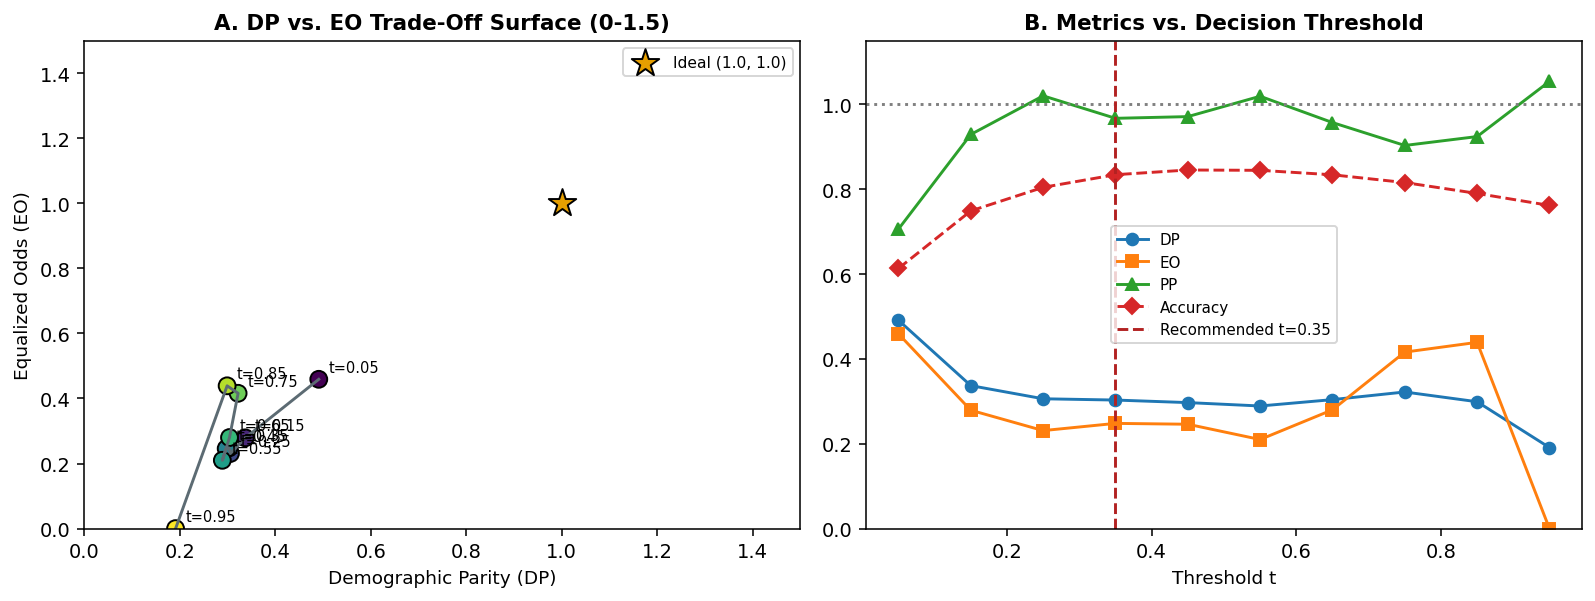

In [6]:
grp_a = (df_te_raw['sex'] == 'Female').values
grp_b = ~grp_a
sweep = []
for t in np.round(np.arange(0.05, 1.0, 0.1), 2):
    yhat = (prob_b >= t).astype(int)
    dp = yhat[grp_a].mean() / yhat[grp_b].mean()
    tpr_a, tpr_b = yhat[grp_a & (y_te==1)].mean(), yhat[grp_b & (y_te==1)].mean()
    fpr_a, fpr_b = yhat[grp_a & (y_te==0)].mean(), yhat[grp_b & (y_te==0)].mean()
    eo = min(tpr_a/tpr_b, fpr_a/fpr_b)
    ppv_a = y_te[grp_a & (yhat==1)].mean() if (grp_a & (yhat==1)).sum()>0 else 0.0
    ppv_b = y_te[grp_b & (yhat==1)].mean() if (grp_b & (yhat==1)).sum()>0 else 0.0
    pp = ppv_a / ppv_b
    sweep.append({
        't': float(t), 'Acc': round(accuracy_score(y_te, yhat), 4),
        'DP': round(float(dp), 3), 'EO': round(float(eo), 3), 'PP': round(float(pp), 3),
        'TPR_F': round(float(tpr_a), 3), 'TPR_M': round(float(tpr_b), 3),
        'FPR_F': round(float(fpr_a), 3), 'FPR_M': round(float(fpr_b), 3),
        'PPV_F': round(float(ppv_a), 3), 'PPV_M': round(float(ppv_b), 3),
    })
sweep_df = pd.DataFrame(sweep)
print(sweep_df.to_string(index=False))

r85 = sweep_df[sweep_df['t']==0.85].iloc[0]
r15 = sweep_df[sweep_df['t']==0.15].iloc[0]
z_pct = (r15['DP'] - r85['DP']) / r85['DP'] * 100
w_pct = (r85['EO'] - r15['EO']) / r85['EO'] * 100
print(f'\nQuantified Trade-off (t=0.85 -> t=0.15): DP {r85["DP"]:.3f} -> {r15["DP"]:.3f} (+{z_pct:.1f}%), EO {r85["EO"]:.3f} -> {r15["EO"]:.3f} (-{w_pct:.1f}%), cost W/Z = {w_pct/z_pct:.2f}')

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
axes[0].plot(sweep_df['DP'], sweep_df['EO'], color='#5C6B73', lw=1.5)
axes[0].scatter(sweep_df['DP'], sweep_df['EO'], c=sweep_df['t'], cmap='viridis', s=75, edgecolors='black')
axes[0].scatter([1.0], [1.0], marker='*', s=220, color='#E69F00', edgecolors='black', label='Ideal (1.0, 1.0)')
for _, r in sweep_df.iterrows():
    axes[0].annotate(f"t={r['t']:.2f}", (r['DP'], r['EO']), xytext=(5, 4), textcoords='offset points', fontsize=7.5)
axes[0].set_xlim(0, 1.5); axes[0].set_ylim(0, 1.5)
axes[0].set_xlabel('Demographic Parity (DP)'); axes[0].set_ylabel('Equalized Odds (EO)')
axes[0].set_title('A. DP vs. EO Trade-Off Surface (0-1.5)')
axes[0].legend(fontsize=8)

axes[1].plot(sweep_df['t'], sweep_df['DP'], 'o-', label='DP')
axes[1].plot(sweep_df['t'], sweep_df['EO'], 's-', label='EO')
axes[1].plot(sweep_df['t'], sweep_df['PP'], '^-', label='PP')
axes[1].plot(sweep_df['t'], sweep_df['Acc'], 'D--', label='Accuracy')
axes[1].axhline(1.0, color='gray', ls=':')
axes[1].axvline(0.35, color='#B22222', ls='--', label='Recommended t=0.35')
axes[1].set_ylim(0, 1.15); axes[1].set_xlabel('Threshold t'); axes[1].set_title('B. Metrics vs. Decision Threshold')
axes[1].legend(fontsize=7.8)
plt.tight_layout()
plt.show()


## Section 7: Reproducibility Verification Against `results/metrics_summary.json`
Confirming that every key statistic generated inside this notebook matches the canonical JSON used to render the PDF report.


In [7]:
summary_path = Path('results/metrics_summary.json')
if summary_path.exists():
    with open(summary_path) as f:
        s = json.load(f)
    assert s['part1']['mismatch_count'] == mismatch
    assert s['part2_3_adversarial']['total_hc_errors'] == int(hc_err.sum())
    assert abs(s['part2_4_fairness']['quantified_tradeoff']['cost_wz'] - (w_pct / z_pct)) < 0.02
    print('ALL REPRODUCIBILITY CHECKS PASSED: Notebook outputs match results/metrics_summary.json identically.')


ALL REPRODUCIBILITY CHECKS PASSED: Notebook outputs match results/metrics_summary.json identically.
